In [7]:
!pip -q install pyuvdata
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [5]:
!pip -q install pyuvdata
import os, glob
RAW = "/content/drive/MyDrive/CS 163/cs163_data"
print("data folder found:", os.path.exists(RAW), "| uvfits:", len(glob.glob(f"{RAW}/*.uvfits")))

data folder found: True | uvfits: 10000


In [6]:
import os, glob, numpy as np, torch, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pyuvdata import UVData

RAW, OUT  = "/content/drive/MyDrive/CS 163/cs163_data", "/content/drive/MyDrive/CS 163/cs163_tensors_sim"
N_SAMPLES = 256              # quick test first; set to 10000 for the full set
N_SRC     = (20, 200)        # point sources per sky (min, max)
NOISE     = 0.05             # thermal noise std, as a fraction of mean |V_sky|
GAINS     = "independent"    # "independent" (like Ruby: amp N(1,0.1), phase U(0,2π)) or "correlated"
CORR_LEN  = 40.0             # metres, only used for "correlated"
SEED, B   = 0, 64
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
print("device:", device)

# ---- 1. antenna positions: same 214 antennas, same order as MG's tensors ----
uv = UVData(); uv.read(sorted(glob.glob(f"{RAW}/*.uvfits"))[0], run_check=False)
ants = np.union1d(uv.ant_1_array, uv.ant_2_array)                     # MG's ordering
try:    pos, nums = uv.telescope.get_enu_antpos(), uv.telescope.antenna_numbers
except AttributeError: pos, nums = uv.get_ENU_antpos()
P = pos[[list(nums).index(a) for a in ants]]                          # (214,3) east,north,up [m]
lam = 299792458.0 / uv.freq_array.ravel()[0]
N = len(ants); assert N == 214
Pt = torch.tensor(P / lam, dtype=torch.float32, device=device)        # in wavelengths

# sanity: baseline lengths from positions should match the file's uvw
cross = uv.ant_1_array != uv.ant_2_array
i, j = np.searchsorted(ants, uv.ant_1_array[cross]), np.searchsorted(ants, uv.ant_2_array[cross])
print("baseline length mismatch (m):",
      np.abs(np.sort(np.linalg.norm(P[j]-P[i], axis=1)) - np.sort(np.linalg.norm(uv.uvw_array[cross], axis=1))).max())

# ---- 2. random skies ----
def random_sky(b):
    K = N_SRC[1]
    on = torch.arange(K, device=device)[None] < torch.randint(N_SRC[0], K+1, (b,1), device=device)
    r, th = 0.95*torch.rand(b,K,device=device).sqrt(), 2*np.pi*torch.rand(b,K,device=device)
    l, m = r*torch.cos(th), r*torch.sin(th)                           # uniform over the visible sky
    n = torch.sqrt(1 - l**2 - m**2)
    flux = torch.rand(b,K,device=device).pow(-1/1.5).clamp(max=1000)  # power law: few bright, many faint
    flux = flux * n**2 * on                                           # simple dipole beam ~ cos^2(zenith angle)
    return l, m, n, flux

def sky_vis(l, m, n, flux):
    ph = Pt[:,0,None]*l[:,None] + Pt[:,1,None]*m[:,None] + Pt[:,2,None]*(n[:,None]-1)   # (b,N,K)
    A = torch.exp(-2j*np.pi*ph)
    V = (A * flux[:,None,:]) @ A.conj().transpose(1,2)                # A diag(flux) A^H
    V.diagonal(dim1=1, dim2=2).zero_()                                # no autos, like MG
    return V

# ---- 3. random gains ----
if GAINS == "correlated":
    d2 = ((Pt[:,None,:2] - Pt[None,:,:2])**2).sum(-1) * lam**2
    Lc = torch.linalg.cholesky(torch.exp(-d2/(2*CORR_LEN**2)) + 1e-4*torch.eye(N, device=device))
def gains(b):
    amp = 1 + 0.1*torch.randn(b,N,device=device)
    ph = 2*np.pi*torch.rand(b,N,device=device) if GAINS == "independent" \
         else (np.pi/2) * torch.randn(b,N,device=device) @ Lc.T
    return amp * torch.exp(1j*ph)

# ---- 4. generate + save in MG's format ----
os.makedirs(OUT, exist_ok=True)
X = np.lib.format.open_memmap(f"{OUT}/X.npy",      "w+", np.float16, (N_SAMPLES,2,N,N))  # observed (input)
T = np.lib.format.open_memmap(f"{OUT}/V_true.npy", "w+", np.float16, (N_SAMPLES,2,N,N))  # true sky vis (target)
Y, M, S = np.zeros((N_SAMPLES,2,N),np.float32), np.ones((N_SAMPLES,N),bool), np.zeros(N_SAMPLES,np.float32)
cats = []

for s0 in tqdm(range(0, N_SAMPLES, B)):
    b = min(B, N_SAMPLES - s0)
    l, m, n, flux = random_sky(b); Vt = sky_vis(l, m, n, flux); g = gains(b)
    Vo = g[:,:,None] * g.conj()[:,None,:] * Vt                        # V_obs = g_i conj(g_j) V_sky
    noise = torch.triu(torch.randn_like(Vt), 1) * NOISE * Vt.abs().mean((1,2), keepdim=True)
    Vo = Vo + noise + noise.conj().transpose(1,2)                     # Hermitian noise, zero diagonal
    sc = Vo.abs().mean((1,2), keepdim=True)                           # MG's normalization
    Vo, Vt = Vo/sc, Vt/sc
    X[s0:s0+b] = torch.stack([Vo.real, Vo.imag], 1).half().cpu().numpy()
    T[s0:s0+b] = torch.stack([Vt.real, Vt.imag], 1).half().cpu().numpy()
    Y[s0:s0+b] = torch.stack([g.real, g.imag], 1).cpu().numpy()
    S[s0:s0+b] = sc.flatten().cpu().numpy()
    cats.append(torch.stack([l, m, flux], 1).cpu().numpy())           # source catalogue per sky

X.flush(); T.flush(); del X, T
np.save(f"{OUT}/Y.npy", Y); np.save(f"{OUT}/M.npy", M); np.save(f"{OUT}/S.npy", S)
np.save(f"{OUT}/sky_catalog.npy", np.concatenate(cats)); np.save(f"{OUT}/antpos_wavelengths.npy", P/lam)
print("saved", N_SAMPLES, "samples to", OUT)

device: cuda
baseline length mismatch (m): 3.126388037344441e-13


  0%|          | 0/4 [00:00<?, ?it/s]

saved 256 samples to /content/drive/MyDrive/CS 163/cs163_tensors_sim


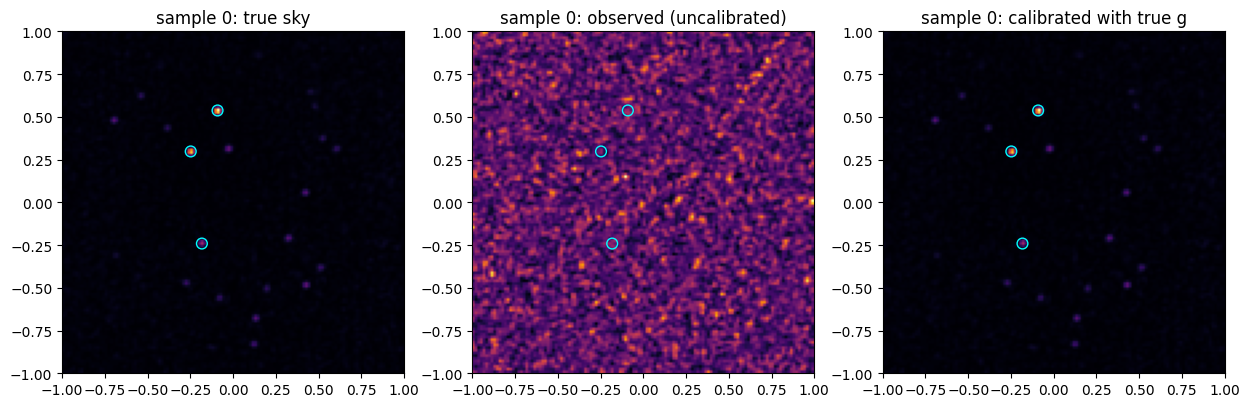

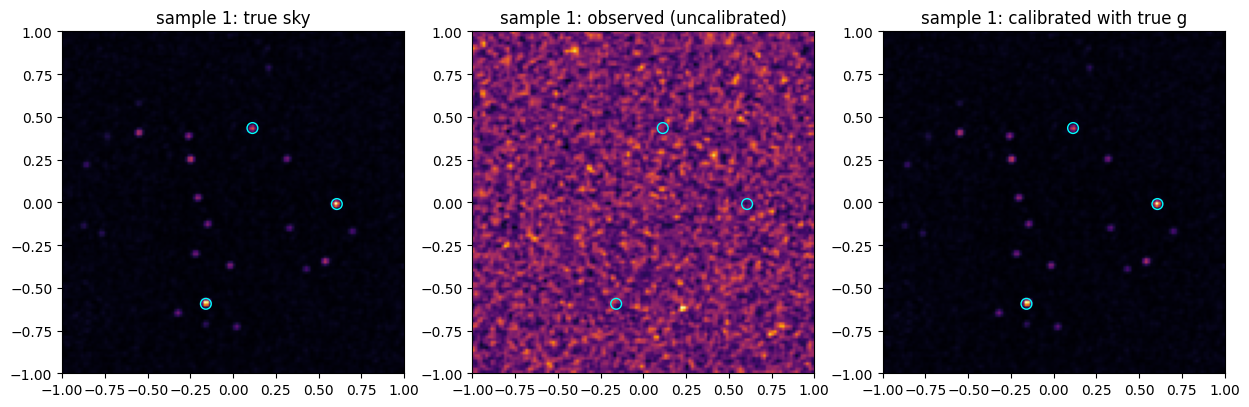

In [8]:
# ---- sanity check: true sky vs observed vs calibrated, with brightest sources circled ----
X = np.load(f"{OUT}/X.npy", mmap_mode="r"); T = np.load(f"{OUT}/V_true.npy", mmap_mode="r")
Y = np.load(f"{OUT}/Y.npy"); cat = np.load(f"{OUT}/sky_catalog.npy", mmap_mode="r")
PIX = 128
ll = torch.linspace(-1, 1, PIX, device=device); Lg, Mg = torch.meshgrid(ll, ll, indexing="xy")
Apix = torch.exp(-2j*np.pi*(Lg.reshape(-1,1)*Pt[:,0] + Mg.reshape(-1,1)*Pt[:,1]))   # (pix, N)
img = lambda V: ((Apix.conj() @ V) * Apix).sum(-1).real.reshape(PIX, PIX).cpu()

def show(k):
    c = lambda a: torch.tensor(a[k,0].astype(np.float32) + 1j*a[k,1].astype(np.float32), device=device)
    g = torch.tensor(Y[k,0] + 1j*Y[k,1], device=device)
    Vobs = c(X); G = g[:,None] * g.conj()[None,:]
    fl = cat[k,2]; big = fl > np.percentile(fl[fl>0], 90)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for a, V, t in zip(ax, [c(T), Vobs, Vobs/G], ["true sky", "observed (uncalibrated)", "calibrated with true g"]):
        a.imshow(img(V), origin="lower", extent=[-1,1,-1,1], cmap="inferno"); a.set_title(f"sample {k}: {t}")
        a.scatter(cat[k,0][big], cat[k,1][big], s=60, facecolors="none", edgecolors="cyan")
    plt.show()

for k in [0, 1]: show(k)